Starting Cuckoo Search Optimization...

Iteration: 50 | Best Fitness: 29500.0
Iteration: 100 | Best Fitness: 29500.0
Iteration: 150 | Best Fitness: 29500.0
Iteration: 200 | Best Fitness: 29500.0
Iteration: 250 | Best Fitness: 29500.0
Iteration: 300 | Best Fitness: 29500.0
Iteration: 350 | Best Fitness: 29500.0
Iteration: 400 | Best Fitness: 29500.0
Iteration: 450 | Best Fitness: 29500.0
Iteration: 500 | Best Fitness: 29500.0

 CUCKOO SEARCH OPTIMIZATION RESULTS
Minimum Network Cost: 29500.0
Best Fitness Value: 29500.0

OPTIMAL PIPE DIAMETERS
Pipe 1: 150 mm
Pipe 2: 100 mm
Pipe 3: 100 mm
Pipe 4: 100 mm
Pipe 5: 100 mm
Pipe 6: 100 mm
Pipe 7: 100 mm

NODE PRESSURE
Node 1: 63.309 m
Node 2: 52.212 m
Node 3: 51.637 m
Node 4: 49.597 m
Node 5: 44.641 m
Node 6: 49.920 m
Node 7: 46.250 m

PIPE VELOCITY
Pipe 1: 1.358 m/s
Pipe 2: 1.401 m/s
Pipe 3: 1.273 m/s
Pipe 4: 0.382 m/s
Pipe 5: 0.509 m/s
Pipe 6: 0.382 m/s
Pipe 7: 0.255 m/s

 HYDRAULIC CONSTRAINT VALIDATION
Minimum Pressure: 20.0 m
Maximum Veloc

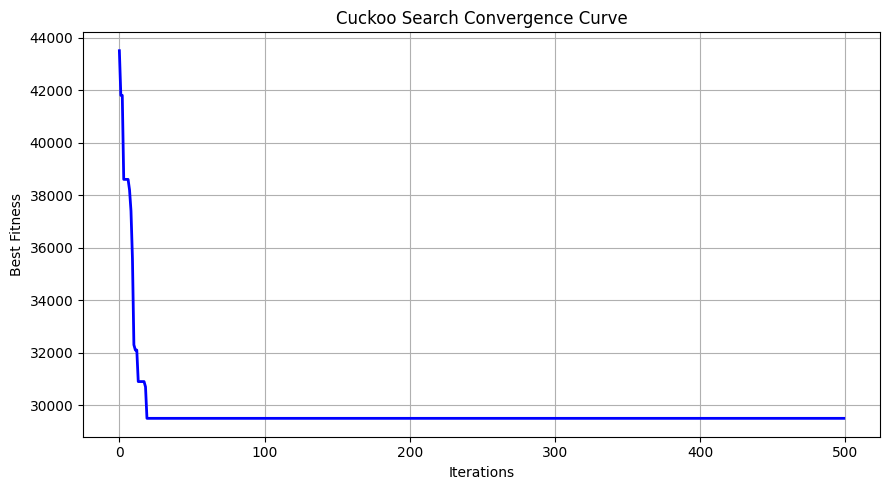

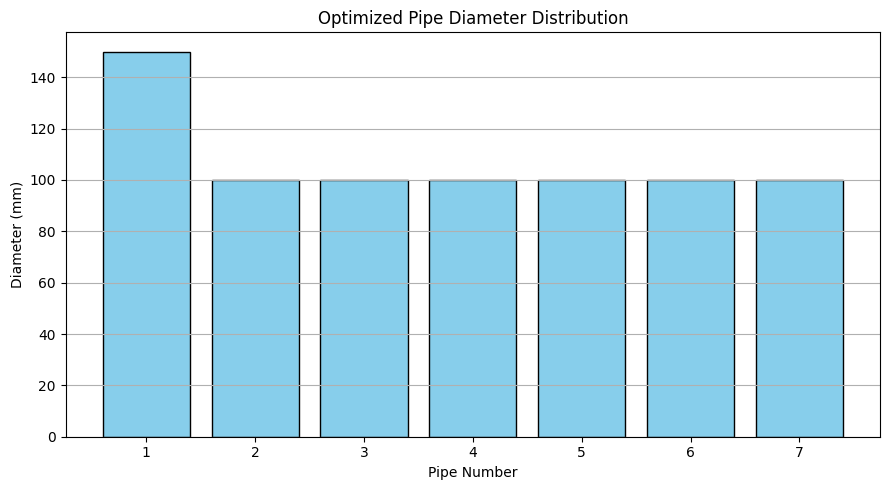

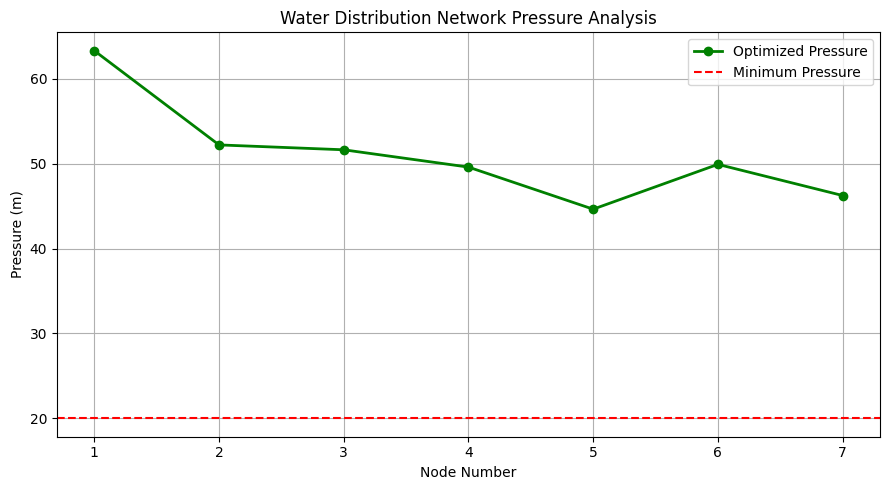


FINAL OPTIMIZED PIPE DESIGN


,Pipe,Length (m),Flow (m3/s),Diameter (mm),Velocity (m/s),Head Loss (m)
0,P1,500.0,0.024,150.0,1.358122,6.691478
1,P2,400.0,0.011,100.0,1.400563,9.096212
2,P3,350.0,0.010,100.0,1.273240,6.671283
3,P4,300.0,0.003,100.0,0.381972,0.615023
4,P5,450.0,0.004,100.0,0.509296,1.571697
5,P6,350.0,0.003,100.0,0.381972,0.717526
6,P7,400.0,0.002,100.0,0.254648,0.386998


,Pipe,Diameter (mm),Unit Cost,Pipe Length (m),Total Cost
0,P1,150.0,14.0,500.0,7000.0
1,P2,100.0,10.0,400.0,4000.0
2,P3,100.0,10.0,350.0,3500.0
3,P4,100.0,10.0,300.0,3000.0
4,P5,100.0,10.0,450.0,4500.0
5,P6,100.0,10.0,350.0,3500.0
6,P7,100.0,10.0,400.0,4000.0



TOTAL OPTIMIZED COST: 29500.0


In [1]:
# ============================================================
# WATER DISTRIBUTION NETWORK OPTIMIZATION USING
# CUCKOO SEARCH ALGORITHM (CSA)
# Google Colab Implementation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

np.random.seed(42)

# ============================================================
# 1. DEFINE WATER DISTRIBUTION NETWORK
# ============================================================

# Node 0 = Reservoir

nodes = [0, 1, 2, 3, 4, 5, 6, 7]

# Elevation of nodes (m)
elevation = np.array([
    0, 10, 12, 15, 14, 18, 16, 20
], dtype=float)

# Water demand (m3/s)
demand = np.array([
    0, 0.003, 0.004, 0.005,
    0.003, 0.004, 0.003, 0.002
])

# Pipe connections (parent, child)
pipes = [
    (0, 1),
    (1, 2),
    (1, 3),
    (2, 4),
    (2, 5),
    (3, 6),
    (3, 7)
]

# Pipe lengths (m)
pipe_length = np.array([
    500, 400, 350, 300, 450, 350, 400
], dtype=float)

# Available commercial pipe diameters (m)
diameters = np.array([
    0.10, 0.15, 0.20,
    0.25, 0.30, 0.35
])

# Pipe installation cost per metre
pipe_cost = np.array([
    10, 14, 20, 28, 38, 52
], dtype=float)

# Hydraulic parameters
reservoir_head = 80.0
C_HW = 130.0

minimum_pressure = 20.0
maximum_velocity = 2.5


# ============================================================
# 2. HYDRAULIC ANALYSIS
# ============================================================

def hydraulic_analysis(solution):

    indices = np.clip(
        np.rint(solution).astype(int),
        0, len(diameters)-1
    )

    D = diameters[indices]

    # Calculate pipe flow using downstream demands
    accumulated_demand = demand.copy()

    Q = np.zeros(len(pipes))

    # Reverse order for the branched network
    for i in reversed(range(len(pipes))):

        parent, child = pipes[i]

        Q[i] = accumulated_demand[child]

        accumulated_demand[parent] += Q[i]

    # Calculate velocity
    area = np.pi * D**2 / 4

    V = Q / area

    # Hazen-Williams head loss
    H = (
        10.67 * pipe_length * Q**1.852
        / (C_HW**1.852 * D**4.871)
    )

    # Calculate hydraulic grade
    hydraulic_grade = np.zeros(len(nodes))

    hydraulic_grade[0] = reservoir_head

    for i, (parent, child) in enumerate(pipes):

        hydraulic_grade[child] = (
            hydraulic_grade[parent] - H[i]
        )

    # Pressure head
    P = hydraulic_grade - elevation

    return D, Q, V, P, H


# ============================================================
# 3. OBJECTIVE FUNCTION AND FITNESS
# ============================================================

def objective_function(solution):

    indices = np.clip(
        np.rint(solution).astype(int),
        0, len(diameters)-1
    )

    total_cost = np.sum(
        pipe_length * pipe_cost[indices]
    )

    return total_cost


def fitness(solution):

    D, Q, V, P, H = hydraulic_analysis(solution)

    cost = objective_function(solution)

    # Pressure violations
    pressure_violation = np.maximum(
        0, minimum_pressure - P[1:]
    )

    # Velocity violations
    velocity_violation = np.maximum(
        0, V - maximum_velocity
    )

    # Penalty function
    penalty = (
        1e8 * np.sum(pressure_violation**2)
        + 1e8 * np.sum(velocity_violation**2)
    )

    return cost + penalty


# ============================================================
# 4. LEVY FLIGHT
# ============================================================

def levy_flight(beta=1.5):

    sigma = (
        math.gamma(1 + beta)
        * np.sin(np.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta * 2**((beta - 1) / 2)
        )
    )**(1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    step = u / (abs(v)**(1/beta) + 1e-10)

    return step


# ============================================================
# 5. CUCKOO SEARCH PARAMETERS
# ============================================================

N_NESTS = 30
MAX_ITERATIONS = 500

PA = 0.25
ALPHA = 0.5

N_VARIABLES = len(pipes)
N_DIAMETERS = len(diameters)


# ============================================================
# 6. CUCKOO SEARCH OPTIMIZATION
# ============================================================

def cuckoo_search():

    # Initialize nests
    nests = np.random.uniform(
        0, N_DIAMETERS-1,
        (N_NESTS, N_VARIABLES)
    )

    fitness_values = np.array([
        fitness(nest) for nest in nests
    ])

    best_index = np.argmin(fitness_values)

    best_solution = nests[best_index].copy()

    best_fitness = fitness_values[best_index]

    convergence = []

    # Main iteration process
    for iteration in range(MAX_ITERATIONS):

        # Generate new solutions using Levy flights
        for i in range(N_NESTS):

            levy_steps = np.array([
                levy_flight()
                for _ in range(N_VARIABLES)
            ])

            new_solution = (
                nests[i]
                + ALPHA * levy_steps
                * (nests[i] - best_solution)
            )

            new_solution = np.clip(
                new_solution,
                0,
                N_DIAMETERS-1
            )

            new_fitness = fitness(new_solution)

            # Greedy selection
            if new_fitness < fitness_values[i]:

                nests[i] = new_solution

                fitness_values[i] = new_fitness

        # Abandon worst nests
        n_abandon = max(
            1, int(PA * N_NESTS)
        )

        worst_indices = np.argsort(
            fitness_values
        )[-n_abandon:]

        for i in worst_indices:

            nests[i] = np.random.uniform(
                0,
                N_DIAMETERS-1,
                N_VARIABLES
            )

            fitness_values[i] = fitness(nests[i])

        # Update global best
        best_index = np.argmin(fitness_values)

        if fitness_values[best_index] < best_fitness:

            best_fitness = fitness_values[best_index]

            best_solution = nests[best_index].copy()

        convergence.append(best_fitness)

        if (iteration+1) % 50 == 0:

            print(
                "Iteration:",
                iteration+1,
                "| Best Fitness:",
                round(best_fitness, 2)
            )

    return best_solution, best_fitness, convergence


# ============================================================
# 7. EXECUTE OPTIMIZATION
# ============================================================

print("Starting Cuckoo Search Optimization...\n")

best_solution, best_fitness, convergence = cuckoo_search()

D, Q, V, P, H = hydraulic_analysis(best_solution)

total_cost = objective_function(best_solution)


# ============================================================
# 8. DISPLAY OPTIMAL RESULTS
# ============================================================

print("\n======================================")
print(" CUCKOO SEARCH OPTIMIZATION RESULTS")
print("======================================")

print("Minimum Network Cost:", round(total_cost, 2))

print("Best Fitness Value:", round(best_fitness, 2))

print("\nOPTIMAL PIPE DIAMETERS")

for i in range(len(pipes)):

    print(
        f"Pipe {i+1}: {D[i]*1000:.0f} mm"
    )

print("\nNODE PRESSURE")

for i in range(1, len(nodes)):

    print(
        f"Node {i}: {P[i]:.3f} m"
    )

print("\nPIPE VELOCITY")

for i in range(len(pipes)):

    print(
        f"Pipe {i+1}: {V[i]:.3f} m/s"
    )


# ============================================================
# 9. CONSTRAINT VALIDATION
# ============================================================

pressure_ok = np.all(
    P[1:] >= minimum_pressure
)

velocity_ok = np.all(
    V <= maximum_velocity
)

print("\n======================================")
print(" HYDRAULIC CONSTRAINT VALIDATION")
print("======================================")

print("Minimum Pressure:", minimum_pressure, "m")

print("Maximum Velocity:", maximum_velocity, "m/s")

print("Pressure Constraint:", pressure_ok)

print("Velocity Constraint:", velocity_ok)

if pressure_ok and velocity_ok:

    print("\nFINAL RESULT: FEASIBLE DESIGN")

else:

    print("\nFINAL RESULT: INFEASIBLE DESIGN")


# ============================================================
# 10. CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(9,5))

plt.plot(
    convergence,
    color="blue",
    linewidth=2
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")

plt.title(
    "Cuckoo Search Convergence Curve"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 11. OPTIMIZED PIPE DIAMETER GRAPH
# ============================================================

plt.figure(figsize=(9,5))

plt.bar(
    range(1, len(D)+1),
    D*1000,
    color="skyblue",
    edgecolor="black"
)

plt.xlabel("Pipe Number")

plt.ylabel("Diameter (mm)")

plt.title(
    "Optimized Pipe Diameter Distribution"
)

plt.xticks(range(1, len(D)+1))

plt.grid(axis="y")

plt.tight_layout()

plt.show()


# ============================================================
# 12. NODE PRESSURE GRAPH
# ============================================================

plt.figure(figsize=(9,5))

plt.plot(
    nodes[1:],
    P[1:],
    marker="o",
    color="green",
    linewidth=2,
    label="Optimized Pressure"
)

plt.axhline(
    minimum_pressure,
    color="red",
    linestyle="--",
    label="Minimum Pressure"
)

plt.xlabel("Node Number")

plt.ylabel("Pressure (m)")

plt.title(
    "Water Distribution Network Pressure Analysis"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 13. FINAL RESULTS TABLE
# ============================================================

results = pd.DataFrame({

    "Pipe": [f"P{i+1}" for i in range(len(D))],

    "Length (m)": pipe_length,

    "Flow (m3/s)": Q,

    "Diameter (mm)": D*1000,

    "Velocity (m/s)": V,

    "Head Loss (m)": H

})

print("\nFINAL OPTIMIZED PIPE DESIGN")

display(results)


# ============================================================
# 14. COST SUMMARY
# ============================================================

cost_results = pd.DataFrame({

    "Pipe": [f"P{i+1}" for i in range(len(D))],

    "Diameter (mm)": D*1000,

    "Unit Cost": pipe_cost[
        np.clip(
            np.rint(best_solution).astype(int),
            0, N_DIAMETERS-1
        )
    ],

    "Pipe Length (m)": pipe_length,

    "Total Cost": (
        pipe_length * pipe_cost[
            np.clip(
                np.rint(best_solution).astype(int),
                0, N_DIAMETERS-1
            )
        ]
    )

})

display(cost_results)

print(
    "\nTOTAL OPTIMIZED COST:",
    round(total_cost, 2)
)